# ch01_1. 심장질환 딥러닝 이진분류

## 실제 CSV 데이터로 딥러닝 이진분류하기

## 개요

- `heart.csv`를 불러와 데이터 구조를 확인합니다.
- **(변경)** 기존 로지스틱 분류의 단일 선형층을 Hidden Layer(은닉층)와 ReLU(렐루)가 있는 MLP(다층 퍼셉트론)로 확장합니다.
- Confusion Matrix(컨퓨전 매트릭스, 혼동행렬)와 임계값의 의미를 이해합니다.


## 1. 라이브러리와 CSV 파일 준비

 다음 라이브러리를 사용합니다.

- Pandas(판다스): CSV 읽기와 표 형태 데이터 처리
- scikit-learn(사이킷런): 훈련·테스트 데이터 분할
- PyTorch(파이토치): 모델 학습
- Matplotlib(맷플롯립): 그래프 출력

파일 이름은 `heart.csv` 또는 `heart(1).csv`를 사용할 수 있습니다.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

torch.manual_seed(42)

# 두 파일 이름 중 현재 폴더에 있는 파일을 사용합니다.
data_path = Path("heart.csv")

if not data_path.exists():
    data_path = Path("heart(1).csv")

# Colab에서 파일이 없으면 업로드합니다.
if not data_path.exists():
    try:
        from google.colab import files
        files.upload()

        data_path = Path("heart.csv")

        if not data_path.exists():
            data_path = Path("heart(1).csv")

    except ImportError:
        pass

if not data_path.exists():
    raise FileNotFoundError(
        "현재 폴더에 heart.csv 또는 heart(1).csv를 넣어 주세요."
    )

heart_data = pd.read_csv(data_path)

print("사용 파일:", data_path.name)
print("데이터 shape:", heart_data.shape)

사용 파일: heart.csv
데이터 shape: (303, 14)


## 2. 데이터 구조 확인

데이터는 303행, 14열로 구성됩니다.

- 입력 특성: 13개
- 목표값: `target`
- `target=0`: 심장질환 없음
- `target=1`: 심장질환 있음

중복 행은 바로 삭제하지 않고 개수만 확인합니다.
실무에서는 중복이 실제 반복 측정인지 입력 오류인지 확인한 뒤 처리합니다.

In [2]:
print("앞부분 5행:")
print(heart_data.head())

print()
print("결측값 수:", heart_data.isna().sum().sum())
print("중복 행 수:", heart_data.duplicated().sum())

print()
print("target 클래스별 개수:")
print(
    heart_data["target"]
    .value_counts()
    .sort_index()
)

앞부분 5행:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  

결측값 수: 0
중복 행 수: 1

target 클래스별 개수:
target
0    138
1    165
Name: count, dtype: int64


## 3. 주요 열의 의미

| 열 이름 | 의미 |
|---|---|
| `age` | 나이 |
| `sex` | 성별 코드 |
| `cp` | Chest Pain(체스트 페인, 흉통) 유형 |
| `trestbps` | 안정 시 혈압 |
| `chol` | 혈중 콜레스테롤 |
| `fbs` | 공복 혈당 기준 초과 여부 |
| `restecg` | 안정 시 심전도 결과 |
| `thalach` | 최대 심박수 |
| `exang` | 운동 유발 협심증 여부 |
| `oldpeak` | 운동 후 ST 분절 저하 |
| `slope` | ST 분절 기울기 |
| `ca` | 주요 혈관 수 코드 |
| `thal` | Thalassemia(탈라세미아, 지중해빈혈 관련 검사) 코드 |
| `target` | 심장질환 여부 |

`cp`, `restecg`, `slope`, `ca`, `thal`은 숫자로 저장되어 있지만 연속적인 측정값이 아니라 범주 코드입니다.

## 4. 입력과 목표값 분리

- 입력 $X$: `target`을 제외한 13개 특성
- 목표값 $y$: `target`

모델이 정답을 미리 보지 않도록 `target`은 입력에 포함하지 않습니다.

In [3]:
X = heart_data.drop(
    columns="target"
).copy()

y = heart_data[["target"]].astype(
    np.float32
)

print("원본 입력 shape:", X.shape)
print("목표값 shape:", y.shape)

원본 입력 shape: (303, 13)
목표값 shape: (303, 1)


## 5. 범주형 특성 원핫 인코딩

예를 들어 `cp`의 0, 1, 2, 3은 크기의 순서가 아니라 서로 다른 흉통 유형입니다.

따라서 각 범주를 별도의 0과 1 열로 바꿉니다.

- 연속형: `age`, `trestbps`, `chol`, `thalach`, `oldpeak`
- 이진형: `sex`, `fbs`, `exang`
- 다범주형: `cp`, `restecg`, `slope`, `ca`, `thal`

> **범주 코드는 이름표이지 측정량이 아닙니다.**

In [4]:
continuous_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
]

categorical_columns = [
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal",
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=np.float32,
)

X_encoded = X_encoded.astype(
    np.float32
)

print("변환 전 shape:", X.shape)
print("변환 후 shape:", X_encoded.shape)
print("최종 입력 특성 수:", X_encoded.shape[1])

변환 전 shape: (303, 13)
변환 후 shape: (303, 27)
최종 입력 특성 수: 27


## 6. 훈련 데이터와 테스트 데이터 분리

- 훈련 데이터: 80%
- 테스트 데이터: 20%
- `stratify=y`: 클래스 0과 1의 비율을 비슷하게 유지
- `random_state=42`: 다시 실행해도 같은 분할 결과 사용

테스트 데이터는 모델 학습에 사용하지 않습니다.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# 이후 값 변경을 안전하게 하기 위해 복사합니다.
X_train = X_train.copy()
X_test = X_test.copy()

print("훈련 입력 shape:", X_train.shape)
print("테스트 입력 shape:", X_test.shape)

print()
print(
    "훈련 target=1 비율:",
    round(y_train["target"].mean(), 4),
)

print(
    "테스트 target=1 비율:",
    round(y_test["target"].mean(), 4),
)

훈련 입력 shape: (242, 27)
테스트 입력 shape: (61, 27)

훈련 target=1 비율: 0.5455
테스트 target=1 비율: 0.541


## 7. 연속형 특성 표준화

연속형 특성은 숫자의 범위가 서로 다릅니다.

$$
x_{\mathrm{scaled}}
=
\frac{x-\mu_{\mathrm{train}}}
{\sigma_{\mathrm{train}}}
$$

- 평균과 표준편차는 훈련 데이터에서만 계산
- 테스트 데이터에는 훈련 데이터의 평균과 표준편차 적용
- 이진형과 원핫 인코딩된 열은 0과 1을 그대로 유지

테스트 데이터의 통계량을 미리 사용하면 Data Leakage(데이터 리키지, 데이터 누출)가 발생합니다.

In [6]:
train_mean = X_train[
    continuous_columns
].mean()

train_std = X_train[
    continuous_columns
].std()

train_std = train_std.replace(
    0,
    1,
)

X_train.loc[:, continuous_columns] = (
    X_train[continuous_columns] - train_mean
) / train_std

X_test.loc[:, continuous_columns] = (
    X_test[continuous_columns] - train_mean
) / train_std

print("표준화 후 훈련 평균:")
print(
    X_train[continuous_columns]
    .mean()
    .round(3)
)

print()
print("표준화 후 훈련 표준편차:")
print(
    X_train[continuous_columns]
    .std()
    .round(3)
)

표준화 후 훈련 평균:
age        -0.0
trestbps    0.0
chol        0.0
thalach     0.0
oldpeak    -0.0
dtype: float32

표준화 후 훈련 표준편차:
age         1.0
trestbps    1.0
chol        1.0
thalach     1.0
oldpeak     1.0
dtype: float32


## 8. Tensor로 변환

PyTorch 모델에 입력하기 위해 DataFrame(데이터프레임)을 Tensor로 변환합니다.

- 입력 shape: `[데이터 수, 입력 특성 수]`
- 목표값 shape: `[데이터 수, 1]`

In [7]:
X_train_tensor = torch.tensor(
    X_train.to_numpy(),
    dtype=torch.float32,
)

X_test_tensor = torch.tensor(
    X_test.to_numpy(),
    dtype=torch.float32,
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32,
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32,
)

input_size = X_train_tensor.shape[1]

print("입력 특성 수:", input_size)
print(
    "훈련 Tensor:",
    X_train_tensor.shape,
    y_train_tensor.shape,
)
print(
    "테스트 Tensor:",
    X_test_tensor.shape,
    y_test_tensor.shape,
)

입력 특성 수: 27
훈련 Tensor: torch.Size([242, 27]) torch.Size([242, 1])
테스트 Tensor: torch.Size([61, 27]) torch.Size([61, 1])


## 9. 딥러닝 이진분류 모델

> **(변경)** 기존 `nn.Linear(input_size, 1)` 단일 계층에 Hidden Layer(은닉층)와 ReLU(렐루)를 추가합니다.

$$
\text{Input} \rightarrow \text{Linear} \rightarrow \text{ReLU} \rightarrow \text{Linear} \rightarrow \text{ReLU} \rightarrow \text{Linear} \rightarrow \text{Logit}
$$

- **(변경)** 은닉층을 추가하여 여러 특성의 비선형 조합을 학습합니다.
- **(변경)** 은닉층 뒤에 `ReLU()` 활성화 함수를 사용합니다.
- 출력층은 이진분류이므로 Logit(로짓) 1개를 출력합니다.
- 손실함수 `BCEWithLogitsLoss()`는 그대로 사용합니다.
- 예측할 때만 `torch.sigmoid()`를 사용합니다.


In [ ]:
# ============================================================
# (변경 전) Logistic Regression(로지스틱 회귀) 모델
# 기존 코드는 삭제하지 않고 비교를 위해 주석으로 유지합니다.
# ============================================================
# torch.manual_seed(42)
#
# model = nn.Linear(
#     input_size,
#     1,
# )
#
# loss_function = nn.BCEWithLogitsLoss()
#
# optimizer = torch.optim.SGD(
#     model.parameters(),
#     lr=0.05,
# )
#
# print(model)
# print("가중치 shape:", model.weight.shape)
# print("편향 shape:", model.bias.shape)
# ============================================================
# (변경 후) Deep Learning(딥러닝) MLP(다층 퍼셉트론) 모델
# 변경 핵심: Hidden Layer(은닉층) + ReLU(렐루) 추가
# ============================================================
torch.manual_seed(42)

# (변경) 단일 Linear 계층을 MLP 구조로 확장
model = nn.Sequential(
    nn.Linear(input_size, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)

# 손실함수는 기존 이진분류와 동일
loss_function = nn.BCEWithLogitsLoss()

# Optimizer(옵티마이저)도 기존 구조를 그대로 사용
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05,
)

print(model)

# (변경) MLP에서는 각 Linear 계층의 shape를 확인
print("입력층 가중치 shape:", model[0].weight.shape)
print("은닉층 가중치 shape:", model[2].weight.shape)
print("출력층 가중치 shape:", model[4].weight.shape)


## 10. 모델 학습

학습 순서는 와 같습니다.

$$
\text{로짓 계산}
\rightarrow
\text{손실 계산}
\rightarrow
\text{역전파}
\rightarrow
\text{가중치 갱신}
$$

In [9]:
epochs = 2000
loss_history = []

model.train()

for epoch in range(epochs):
    # 1. 로짓 계산
    logits = model(
        X_train_tensor
    )

    # 2. BCE 손실 계산
    loss = loss_function(
        logits,
        y_train_tensor,
    )

    # 3. 이전 기울기 초기화
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치 갱신
    optimizer.step()

    loss_history.append(
        loss.item()
    )

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

처음 Loss: 0.7883331179618835
마지막 Loss: 0.30518838763237


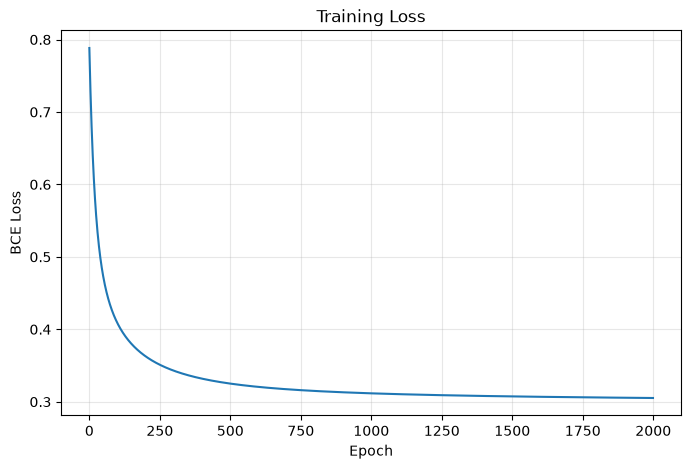

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 11. 확률과 클래스 예측

예측 과정은 다음 순서입니다.

$$
\text{Logit}
\rightarrow
\text{Sigmoid}
\rightarrow
\text{Probability}
\rightarrow
\text{Class}
$$

기본 임계값은 0.5입니다.

- 확률 0.5 이상 → 클래스 1
- 확률 0.5 미만 → 클래스 0

In [11]:
threshold = 0.5

model.eval()

with torch.no_grad():
    train_logits = model(
        X_train_tensor
    )

    test_logits = model(
        X_test_tensor
    )

    train_probabilities = torch.sigmoid(
        train_logits
    )

    test_probabilities = torch.sigmoid(
        test_logits
    )

    train_predictions = (
        train_probabilities >= threshold
    ).float()

    test_predictions = (
        test_probabilities >= threshold
    ).float()

print("테스트 예측 예시 10개")

for actual, probability, predicted in zip(
    y_test_tensor[:10],
    test_probabilities[:10],
    test_predictions[:10],
):
    print(
        f"실제 {int(actual.item())} | "
        f"확률 {probability.item():.4f} | "
        f"예측 {int(predicted.item())}"
    )

테스트 예측 예시 10개
실제 0 | 확률 0.0148 | 예측 0
실제 0 | 확률 0.0875 | 예측 0
실제 0 | 확률 0.0035 | 예측 0
실제 0 | 확률 0.9050 | 예측 1
실제 0 | 확률 0.3307 | 예측 0
실제 0 | 확률 0.0398 | 예측 0
실제 1 | 확률 0.9536 | 예측 1
실제 0 | 확률 0.1673 | 예측 0
실제 1 | 확률 0.9946 | 예측 1
실제 0 | 확률 0.4257 | 예측 0


## 12. 혼동행렬과 평가지표

| 구분 | 의미 |
|---|---|
| TP(티피) | 실제 1을 1로 예측 |
| TN(티엔) | 실제 0을 0으로 예측 |
| FP(에프피) | 실제 0을 1로 잘못 예측 |
| FN(에프엔) | 실제 1을 0으로 잘못 예측 |

$$
\mathrm{Accuracy}
=
\frac{TP+TN}
{TP+TN+FP+FN}
$$

$$
\mathrm{Precision}
=
\frac{TP}
{TP+FP}
$$

$$
\mathrm{Recall}
=
\frac{TP}
{TP+FN}
$$

$$
F1
=
2
\times
\frac{
\mathrm{Precision}
\times
\mathrm{Recall}
}{
\mathrm{Precision}
+
\mathrm{Recall}
}
$$

의료 선별 문제에서는 실제 환자를 놓치는 FN을 줄이는 것이 중요하므로 Recall도 함께 확인합니다.

In [12]:
def calculate_metrics(
    targets,
    predictions,
):
    targets = targets.reshape(-1)
    predictions = predictions.reshape(-1)

    tp = int(
        ((targets == 1) & (predictions == 1)).sum()
    )

    tn = int(
        ((targets == 0) & (predictions == 0)).sum()
    )

    fp = int(
        ((targets == 0) & (predictions == 1)).sum()
    )

    fn = int(
        ((targets == 1) & (predictions == 0)).sum()
    )

    accuracy = (
        tp + tn
    ) / len(targets)

    precision = tp / max(
        tp + fp,
        1,
    )

    recall = tp / max(
        tp + fn,
        1,
    )

    f1 = (
        2 * precision * recall
        / max(precision + recall, 1e-12)
    )

    return {
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


train_metrics = calculate_metrics(
    y_train_tensor,
    train_predictions,
)

test_metrics = calculate_metrics(
    y_test_tensor,
    test_predictions,
)

print("[훈련 데이터]")

for name, value in train_metrics.items():
    print(f"{name:9s}: {value:.4f}")

print()
print("[테스트 데이터]")

for name, value in test_metrics.items():
    print(f"{name:9s}: {value:.4f}")

[훈련 데이터]
TP       : 120.0000
TN       : 91.0000
FP       : 19.0000
FN       : 12.0000
Accuracy : 0.8719
Precision: 0.8633
Recall   : 0.9091
F1       : 0.8856

[테스트 데이터]
TP       : 30.0000
TN       : 21.0000
FP       : 7.0000
FN       : 3.0000
Accuracy : 0.8361
Precision: 0.8108
Recall   : 0.9091
F1       : 0.8571


## 13. 테스트 데이터 혼동행렬

혼동행렬을 이용하면 맞은 예측과 잘못된 예측을 한눈에 확인할 수 있습니다.

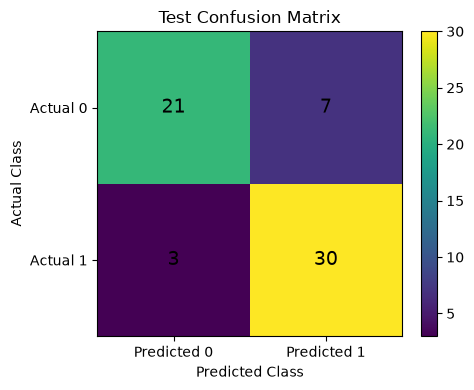

In [13]:
confusion_matrix = np.array(
    [
        [
            test_metrics["TN"],
            test_metrics["FP"],
        ],
        [
            test_metrics["FN"],
            test_metrics["TP"],
        ],
    ]
)

plt.figure(figsize=(5, 4))

plt.imshow(
    confusion_matrix,
)

plt.xticks(
    [0, 1],
    ["Predicted 0", "Predicted 1"],
)

plt.yticks(
    [0, 1],
    ["Actual 0", "Actual 1"],
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Test Confusion Matrix")

for row in range(2):
    for column in range(2):
        plt.text(
            column,
            row,
            confusion_matrix[row, column],
            ha="center",
            va="center",
            fontsize=14,
        )

plt.colorbar()
plt.tight_layout()
plt.show()

## 14. 임계값에 따른 결과 비교

임계값을 낮추면 클래스 1로 판단하는 경우가 늘어납니다.

- Recall이 높아질 수 있음
- FP도 증가할 수 있음

임계값을 높이면 클래스 1로 판단하는 경우가 줄어듭니다.

- FP가 줄어들 수 있음
- FN이 증가할 수 있음

임계값은 정확도만 보고 결정하지 않고 문제의 목적과 오판 비용을 함께 고려합니다.

In [14]:
for threshold in [0.3, 0.5, 0.7]:
    threshold_predictions = (
        test_probabilities >= threshold
    ).float()

    metrics = calculate_metrics(
        y_test_tensor,
        threshold_predictions,
    )

    print(
        f"임계값 {threshold:.1f} | "
        f"Accuracy {metrics['Accuracy']:.4f} | "
        f"Precision {metrics['Precision']:.4f} | "
        f"Recall {metrics['Recall']:.4f} | "
        f"F1 {metrics['F1']:.4f}"
    )

임계값 0.3 | Accuracy 0.7869 | Precision 0.7381 | Recall 0.9394 | F1 0.8267
임계값 0.5 | Accuracy 0.8361 | Precision 0.8108 | Recall 0.9091 | F1 0.8571
임계값 0.7 | Accuracy 0.7705 | Precision 0.8276 | Recall 0.7273 | F1 0.7742


## 16. 핵심 정리

- `heart.csv`는 303개 데이터와 14개 열로 구성됩니다.
- **(변경)** 단일 선형층 대신 `Linear → ReLU → Linear → ReLU → Linear` 구조의 MLP를 사용합니다.
- 모델의 마지막 출력은 Logit(로짓) 1개이며 `BCEWithLogitsLoss()`로 학습합니다.
- 학습 루프, Sigmoid(시그모이드) 확률 변환, 임계값 기반 예측, 혼동행렬과 평가지표 계산은 기존 이진분류와 동일합니다.
- 현재 결과는 교육용 데이터 분석 결과이며 실제 의료 진단 결과가 아닙니다.
